In [1]:
import json
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LassoCV
from joblib import Parallel, delayed
from pathlib import Path
import os, warnings
warnings.simplefilter("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"   

data = Path("../data")
NDM, NDM_P, GDM, GDM_P = "#1F3E64", "#9BB4D1", "#808080", "#D0D0D0"
results = {}


def fit_scm(wide, treated, donors, pre_end, interp=True, cv_intercept=False, agg="mean"):
    y = wide[treated].sum(axis=1, min_count=1) if agg == "sum" else wide[treated].mean(axis=1)
    pre = (wide.index < pd.Timestamp(pre_end)) & y.notna()
    X_pre = wide.loc[pre, [d for d in donors if d in wide.columns]].fillna(0.0)
    y_pre = y[pre].to_numpy()
    if len(y_pre) < 4:
        return None
    cv = LassoCV(alphas=np.geomspace(1e-3, 1e2, 200), cv=min(5, len(y_pre)),
                 positive=True, fit_intercept=cv_intercept, max_iter=20000).fit(X_pre, y_pre)
    w = Lasso(alpha=cv.alpha_, positive=True, fit_intercept=False, max_iter=20000).fit(X_pre, y_pre).coef_
    X_all = wide[X_pre.columns]
    X_all = X_all.interpolate(axis=0).fillna(0.0) if interp else X_all.fillna(0.0)
    return pd.DataFrame({"date": wide.index, "y": y.values, "synth": X_all.to_numpy().dot(w)})


def gap_did(fits, post0, post1=None, weather=None):
    df = pd.concat(fits, ignore_index=True).dropna(subset=["y", "synth"])
    if post1 is not None:
        df = df[df["date"] <= pd.Timestamp(post1)]
    df["T"] = (df["date"] >= pd.Timestamp(post0)).astype(int)
    df["gap"] = df["y"] - df["synth"]
    f = "gap ~ T"
    if weather is not None:
        wc = [c for c in weather.columns if c != "date"]
        df = df.merge(weather, on="date", how="left").dropna(subset=wc)
        f = "gap ~ T + " + " + ".join(wc)
    m = smf.ols(f, df).fit()
    base = df.loc[df["T"] == 1, "synth"].mean()
    return 100*m.params["T"]/base, 100*m.bse["T"]/base

## Boston Free Fare


In [2]:
panel = pd.read_parquet(data/"free_fare/visits/visits.parquet")
panel["date"] = pd.to_datetime(panel["date"])
w = pd.read_csv(data/"free_fare/weather.csv")
w["date"] = pd.to_datetime(w["Date"])
weather = w[["date", "AvgTemperature", "Precipitation", "Snowfall"]]

for design in ["gdm", "ndm"]:
    units = json.load(open(data/f"free_fare/units/{design}.json"))
    treated = units["treated"]
    donors = units.get("donors", units.get("donors_actual"))
    pool = units.get("donors_placebo", donors)

    
    sub = panel[panel["GEOID"].isin(set(treated) | set(donors) | set(pool))]
    means = sub.groupby("GEOID")["post_strat"].mean()
    keep = set(means[(means >= means.quantile(0.1)) & (means <= means.quantile(0.9))].index)
    treated = [t for t in treated if t in keep]
    donors = [d for d in donors if d in keep]
    pool = [d for d in pool if d in keep]

    
    wide = sub[sub["GEOID"].isin(keep)].pivot_table(index="date", columns="GEOID", values="post_strat", aggfunc="sum").sort_index()
    wide = wide[wide.index >= pd.Timestamp("2020-06-01")]

    
    fits = Parallel(n_jobs=-1)(delayed(fit_scm)(wide, [t], donors, "2021-09-01", cv_intercept=True) for t in treated)
    fits = [f for f in fits if f is not None]
    draws = []
    for i in range(100):
        rng = np.random.default_rng(i + 1)
        fake = list(rng.choice(pool, size=len(pool)//2, replace=False))
        rest = [x for x in pool if x not in fake]
        draws.append((fake, rest))
        
    placebo_fits = Parallel(n_jobs=-1)(delayed(fit_scm)(wide, fake, rest, "2021-09-01", cv_intercept=True) for fake, rest in draws)

    ate, se = gap_did(fits, "2021-09-01", weather=weather)
    placebo_ates = [gap_did([f], "2021-09-01", weather=weather)[0] for f in placebo_fits if f is not None]
    p = (sum(abs(x) >= abs(ate) for x in placebo_ates) + 1) / (len(placebo_ates) + 1)
    results[f"Free Fare ({design.upper()})"] = (ate, se, placebo_ates, p)
    print(f"Free Fare {design.upper()}: ATE = {ate:.2f}% [SE {se:.2f}]  p = {p:.3f}")

Free Fare GDM: ATE = 2.21% [SE 0.64]  p = 0.574


Free Fare NDM: ATE = 15.50% [SE 0.55]  p = 0.010


## NYC Open Streets
Weekly post-stratified visits per POI. The post period is each site's operating window; the site's opening week itself belongs to the pre-period of both the SCM fit and the DiD (hence the cutoff one day after the start date). GDM fits on the propensity-filtered ring and draws placebos from the full ring; the DiD controls for weather. As in the Open Streets pipeline, the Lasso penalty is cross-validated with an intercept (the donor weights themselves are fit without one).

In [3]:
sites = [("clh", "CLH", "2021-07-02", "2021-08-31"),
         ("dbp", "DBP", "2021-06-18", "2021-11-27"),
         ("nycdoe_wihs", "WIHS", "2021-09-14", "2021-12-23")]

w = pd.read_csv(data/"open_streets/weather.csv")
w["date"] = pd.to_datetime(w["Date"])
weather = w[["date", "AvgTemperature", "Precipitation", "Snowfall"]]

for org, label, cutoff, post1 in sites:
    panel = pd.read_parquet(data/f"open_streets/{org}/visits/visits.parquet")
    panel["date"] = pd.to_datetime(panel["date"])
    wide = panel.pivot_table(index="date", columns="sg_id", values="post_strat", aggfunc="sum").sort_index()
    wide = wide[wide.index >= pd.Timestamp("2020-04-01")]

    for design in ["gdm", "ndm"]:
        units = json.load(open(data/f"open_streets/{org}/units/{design}.json"))
        treated = units["treated"]
        donors = units.get("donors", units.get("donors_actual"))
        pool = units.get("donors_placebo", donors)

        fits = Parallel(n_jobs=-1)(delayed(fit_scm)(wide, [t], donors, cutoff, interp=False, cv_intercept=True, agg="sum") for t in treated)
        fits = [f for f in fits if f is not None]
        draws = []
        for i in range(100):
            rng = np.random.default_rng(i + 1)
            fake = list(rng.choice(pool, size=max(1, len(pool)//4), replace=False))
            rest = [x for x in pool if x not in fake]
            draws.append((fake, rest))

        placebo_fits = Parallel(n_jobs=-1)(delayed(fit_scm)(wide, fake, rest, cutoff, interp=False, cv_intercept=True, agg="sum") for fake, rest in draws)

        ate, se = gap_did(fits, cutoff, post1, weather=weather)
        placebo_ates = [gap_did([f], cutoff, post1, weather=weather)[0] for f in placebo_fits if f is not None]
        p = (sum(abs(x) >= abs(ate) for x in placebo_ates) + 1) / (len(placebo_ates) + 1)
        results[f"{label} ({design.upper()})"] = (ate, se, placebo_ates, p)
        print(f"{label} {design.upper()}: ATE = {ate:.2f}% [SE {se:.2f}]  p = {p:.3f}")

CLH GDM: ATE = 15.89% [SE 3.90]  p = 0.089


CLH NDM: ATE = 32.59% [SE 4.87]  p = 0.020


DBP GDM: ATE = -6.46% [SE 2.04]  p = 0.554


DBP NDM: ATE = 23.46% [SE 2.25]  p = 0.010


WIHS GDM: ATE = 12.06% [SE 3.91]  p = 0.614


WIHS NDM: ATE = 26.94% [SE 5.06]  p = 0.020


## NYC Congestion Relief Zone
Weekly visits per tract from Placer, 2023-05 onward. Tracts outside the 5th–95th percentile of mean visits are dropped; the DiD controls for weather.

In [4]:
panel = pd.read_parquet(data/"crz/visits/visits.parquet")
panel["date"] = pd.to_datetime(panel["date"])
w = pd.read_csv(data/"crz/weather.csv")
w["date"] = pd.to_datetime(w["Date"])
weather = w[["date", "MaxTemperature", "MinTemperature", "Precipitation"]]

for design in ["gdm", "ndm"]:
    units = json.load(open(data/f"crz/units/{design}.json"))
    treated = units["treated"]
    donors = units.get("donors", units.get("donors_actual"))
    pool = units.get("donors_placebo", donors)

    sub = panel[panel["GEOID"].isin(set(treated) | set(donors) | set(pool))]
    means = sub.groupby("GEOID")["total_visits"].mean()
    keep = set(means[(means > means.quantile(0.05)) & (means < means.quantile(0.95))].index)
    treated = [t for t in treated if t in keep]
    donors = [d for d in donors if d in keep]
    pool = [d for d in pool if d in keep]

    wide = sub[sub["GEOID"].isin(keep)].pivot_table(index="date", columns="GEOID", values="total_visits", aggfunc="sum").sort_index()
    wide = wide[wide.index >= pd.Timestamp("2023-05-01")]


    fits = Parallel(n_jobs=-1)(delayed(fit_scm)(wide, [t], donors, "2025-01-01", cv_intercept=True) for t in treated)
    fits = [f for f in fits if f is not None]
    draws = []
    for i in range(100):
        rng = np.random.default_rng(i + 1)
        fake = list(rng.choice(pool, size=max(1, len(pool)//4), replace=False))
        rest = [x for x in pool if x not in fake]
        draws.append((fake, rest))
    placebo_fits = Parallel(n_jobs=-1)(delayed(fit_scm)(wide, fake, rest, "2025-01-01", cv_intercept=True) for fake, rest in draws)

    
    ate, se = gap_did(fits, "2025-01-01", weather=weather)
    placebo_ates = [gap_did([f], "2025-01-01", weather=weather)[0] for f in placebo_fits if f is not None]
    p = (sum(abs(x) >= abs(ate) for x in placebo_ates) + 1) / (len(placebo_ates) + 1)
    results[f"CRZ ({design.upper()})"] = (ate, se, placebo_ates, p)
    print(f"CRZ {design.upper()}: ATE = {ate:.2f}% [SE {se:.2f}]  p = {p:.3f}")

CRZ GDM: ATE = -6.73% [SE 0.39]  p = 0.030


CRZ NDM: ATE = -1.57% [SE 0.30]  p = 0.198


## Summary
Point = pooled ATE with ±1.96 SE error bars; violin = placebo distribution (5th–95th pct); stars = two-sided empirical placebo p (* <0.05, ** <0.01).

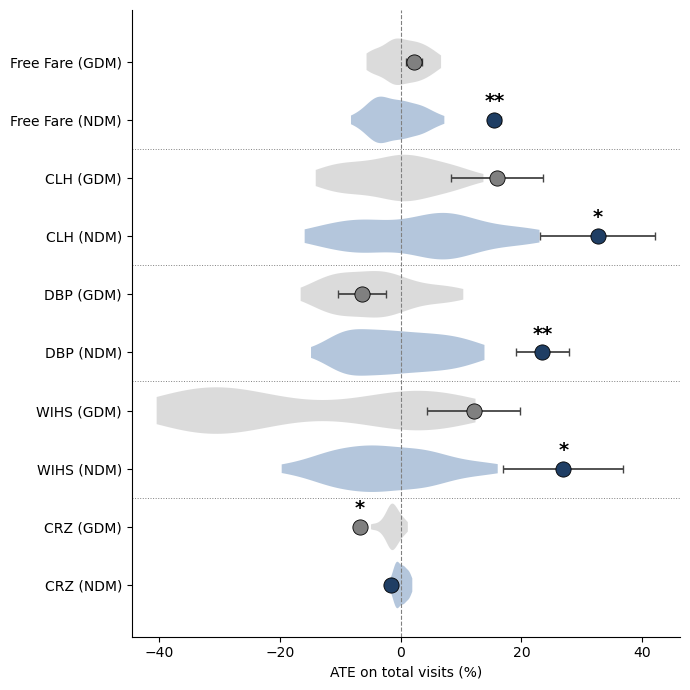

In [5]:
order = ["Free Fare (GDM)", "Free Fare (NDM)", "CLH (GDM)", "CLH (NDM)",
         "DBP (GDM)", "DBP (NDM)", "WIHS (GDM)", "WIHS (NDM)", "CRZ (GDM)", "CRZ (NDM)"]

fig, ax = plt.subplots(figsize=(7, 7))
for yy, name in enumerate(order):
    ate, se, placebos, pv = results[name]
    kind = "ndm" if "NDM" in name else "gdm"
    draws = [x for x in placebos if np.isfinite(x)]
    clip = [x for x in draws if np.percentile(draws, 5) <= x <= np.percentile(draws, 95)]
    
    if len(clip) >= 2 and np.ptp(clip) > 0:
        v = ax.violinplot([clip], positions=[yy], vert=False, showextrema=False, widths=0.8)
        for b in v["bodies"]:
            b.set_facecolor(NDM_P if kind == "ndm" else GDM_P); b.set_alpha(0.75)

    ax.errorbar(ate, yy, xerr=1.96*se, fmt="none", ecolor="#444", capsize=3, lw=1.3)
    ax.scatter(ate, yy, s=120, color=NDM if kind == "ndm" else GDM, edgecolor="black", lw=0.6, zorder=5)
    
    if pv < 0.05:
        ax.text(ate, yy-0.15, "*" * (1 + (pv < 0.01) + (pv < 0.001)), ha="center", va="bottom", fontsize=14, weight="bold")

for sep in [1.5, 3.5, 5.5, 7.5]:
    ax.axhline(sep, ls=":", lw=0.7, color="gray")

ax.axvline(0, ls="--", lw=0.8, color="gray")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("ATE on total visits (%)")

for s in ("top", "right"):
    ax.spines[s].set_visible(False)

plt.tight_layout(); plt.show()